# DA-E01 fuel analysis walkthrough

This notebook reads the built analytical database. Run the documented build pipeline first. Fleet operations are synthetic; no realized savings are claimed.

In [1]:
from pathlib import Path
import duckdb
root = Path.cwd()
if root.name == 'notebooks': root = root.parent
con = duckdb.connect(str(root / 'data/DA-E01.duckdb'), read_only=True)
con.execute("SET TimeZone='UTC'")

## 1. Inspect report versions

Keep initial, revised and retrospective results separate. Each output_id points to a cutoff and source snapshot.

In [2]:
con.sql("SELECT tenant_id, output_id, report_week_start, as_of_time FROM normalized.fuel_report_run ORDER BY tenant_id, report_week_start LIMIT 12").df()

,tenant_id,output_id,report_week_start,as_of_time
0,T01,T01-FUEL-20241230-initial,2024-12-30 08:00:00+00:00,2025-01-08 08:00:00+00:00
1,T01,T01-FUEL-20241230-revised,2024-12-30 08:00:00+00:00,2025-01-13 08:00:00+00:00
2,T01,T01-FUEL-20241230-retrospective,2024-12-30 08:00:00+00:00,2026-10-25 18:57:01+00:00
3,T01,T01-FUEL-20250106-initial,2025-01-06 08:00:00+00:00,2025-01-15 08:00:00+00:00
4,T01,T01-FUEL-20250106-revised,2025-01-06 08:00:00+00:00,2025-01-20 08:00:00+00:00
5,T01,T01-FUEL-20250106-retrospective,2025-01-06 08:00:00+00:00,2026-10-25 18:57:01+00:00
6,T01,T01-FUEL-20250113-initial,2025-01-13 08:00:00+00:00,2025-01-22 08:00:00+00:00
7,T01,T01-FUEL-20250113-revised,2025-01-13 08:00:00+00:00,2025-01-27 08:00:00+00:00
8,T01,T01-FUEL-20250113-retrospective,2025-01-13 08:00:00+00:00,2026-10-25 18:57:01+00:00
9,T01,T01-FUEL-20250120-initial,2025-01-20 08:00:00+00:00,2025-01-29 08:00:00+00:00


## 2. Recalculate the fleet ratio

Use total distance and total consumption from the same accepted intervals, not the arithmetic mean of vehicle MPG.

In [3]:
con.sql("""SELECT SUM(distance_travelled_km) paired_km, SUM(fuel_used_l) paired_l, SUM(distance_travelled_km)/NULLIF(SUM(fuel_used_l),0)*3.785411784/1.609344 fleet_mpg, SUM(valid_paired_seconds)/NULLIF(SUM(expected_observation_seconds),0) coverage FROM normalized.fuel_weekly_metric WHERE output_id LIKE '%-revised'""").df()

,paired_km,paired_l,fleet_mpg,coverage
0,219385.511611,62852.700212,8.210096,0.999491


## 3. Inspect exclusions before interpreting anomalies

Rejected intervals remain visible. A missing or invalid interval is not zero fuel consumption.

In [4]:
con.sql("SELECT accepted, excluded_interval_reason, COUNT(*) n FROM normalized.fuel_paired_interval GROUP BY ALL ORDER BY n DESC").df()

,accepted,excluded_interval_reason,n
0,True,none,731049
1,False,cross_period_unallocatable,6165
2,False,outside_or_ambiguous_task,1554
3,False,ambiguous_assignment,456
4,False,invalid_reading,12
5,False,counter_break,6


## 4. Compare like tasks

**Why:** mixed task weeks can hide operating differences. **Data:** task-specific accepted intervals, vehicle class and expected task time. **How:** compare each vehicle/task with its previous week and with other vehicles in the same tenant, class, task and week. **Interpretation:** at least three peers and 95% coverage are needed for the peer review rule. A difference still requires load, PTO and route investigation.

In [5]:
con.sql("""SELECT tenant_id,vehicle_id,vehicle_class,report_week_start,task_type,l_per_100km,prior_l_per_100km,peer_median_l_per_100km,peer_count,measurement_coverage,comparison_status,review_flag FROM analytics.efficiency_comparison WHERE report_view='revised' ORDER BY (review_flag='review_load_pto_route') DESC,vehicle_id,report_week_start LIMIT 25""").df()

,tenant_id,vehicle_id,vehicle_class,report_week_start,task_type,l_per_100km,prior_l_per_100km,peer_median_l_per_100km,peer_count,measurement_coverage,comparison_status,review_flag
0,T02,T02-V08,heavy_truck,2025-02-17 08:00:00+00:00,regional_delivery,36.716478,33.735012,30.255111,7,1.0,descriptive_peer_comparison,review_load_pto_route
1,T01,T01-V01,heavy_truck,2024-12-30 08:00:00+00:00,linehaul,27.107404,NaN,29.051456,5,1.0,descriptive_peer_comparison,within_review_threshold
2,T01,T01-V01,heavy_truck,2025-01-06 08:00:00+00:00,regional_delivery,29.392300,NaN,30.454371,4,1.0,descriptive_peer_comparison,within_review_threshold
3,T01,T01-V01,heavy_truck,2025-01-06 08:00:00+00:00,linehaul,30.546084,27.107404,29.865316,7,1.0,descriptive_peer_comparison,within_review_threshold
4,T01,T01-V01,heavy_truck,2025-01-13 08:00:00+00:00,regional_delivery,28.068777,29.392300,29.992577,5,1.0,descriptive_peer_comparison,within_review_threshold
5,T01,T01-V01,heavy_truck,2025-01-13 08:00:00+00:00,linehaul,28.125351,30.546084,28.113011,7,1.0,descriptive_peer_comparison,within_review_threshold
6,T01,T01-V01,heavy_truck,2025-01-20 08:00:00+00:00,linehaul,28.729103,28.125351,29.421257,7,1.0,descriptive_peer_comparison,within_review_threshold
7,T01,T01-V01,heavy_truck,2025-01-20 08:00:00+00:00,regional_delivery,28.230064,28.068777,30.856625,7,1.0,descriptive_peer_comparison,within_review_threshold
8,T01,T01-V01,heavy_truck,2025-01-27 08:00:00+00:00,linehaul,29.283410,28.729103,28.279927,7,1.0,descriptive_peer_comparison,within_review_threshold
9,T01,T01-V01,heavy_truck,2025-02-03 08:00:00+00:00,linehaul,27.368842,29.283410,29.846147,7,1.0,descriptive_peer_comparison,within_review_threshold


## 5. Reconcile purchase spend without calling it fuel use

**Why:** a purchase fills stock; it need not be consumed in that week. **Data:** net fuel-only transaction amounts and quantities, including eligible credits. **How:** inspect weekly quantities and price/quantity effects. **Interpretation:** unmatched cohort changes remain a residual; market gaps are comparisons, not realizable savings.

In [6]:
con.sql("""SELECT report_week_start, SUM(purchase_quantity_l) purchased_l, SUM(comparable_fuel_amount) purchase_usd, SUM(purchase_price_effect) price_effect_usd, SUM(purchase_quantity_effect) quantity_effect_usd FROM analytics.fleet_weekly WHERE report_view='revised' GROUP BY report_week_start ORDER BY report_week_start DESC LIMIT 8""").df()

,report_week_start,purchased_l,purchase_usd,price_effect_usd,quantity_effect_usd
0,2025-06-30 07:00:00+00:00,NaN,NaN,NaN,NaN
1,2025-06-23 07:00:00+00:00,3767.657649,4330.44,24.592672,2766.177328
2,2025-06-16 07:00:00+00:00,1346.712836,1539.67,-17.361943,-2460.868057
3,2025-06-09 07:00:00+00:00,3536.481749,4017.90,54.397406,2237.912594
4,2025-06-02 07:00:00+00:00,1563.422790,1725.59,2.318780,-1339.308780
5,2025-05-26 07:00:00+00:00,2803.452342,3062.58,-17.337482,803.347482
6,2025-05-19 07:00:00+00:00,2077.883567,2276.57,17.860686,-459.070686
7,2025-05-12 07:00:00+00:00,2485.332185,2717.78,-55.689282,-135.810718


## 6. Cross-check ECU use against tank balance

**Why:** two measurement paths can disagree. **Data:** common tank-window boundaries, recorded refills/transfers/removals and accepted ECU intervals. **How:** inspect residual and stated uncertainty, together with evidence state. **Interpretation:** a residual outside uncertainty calls for coverage or movement checks; it does not prove theft or waste.

In [7]:
con.sql("""SELECT tenant_id,vehicle_id,period_start_at,period_end_at,balance_consumption_l,ecu_fuel_l,ecu_minus_inventory_l,uncertainty_l,reconciliation_status FROM analytics.inventory_reconciliation ORDER BY ABS(ecu_minus_inventory_l) DESC NULLS LAST LIMIT 15""").df()

,tenant_id,vehicle_id,period_start_at,period_end_at,balance_consumption_l,ecu_fuel_l,ecu_minus_inventory_l,uncertainty_l,reconciliation_status
0,T03,T03-V10,2025-03-31 07:00:00+00:00,2025-04-07 07:00:00+00:00,56.960325,26.097417,-30.862908,4.0,investigate_coverage_or_balance
1,T02,T02-V03,2025-04-28 07:00:00+00:00,2025-05-05 07:00:00+00:00,65.020912,64.577644,-0.443268,4.0,within_measurement_uncertainty
2,T02,T02-V04,2025-02-24 08:00:00+00:00,2025-03-03 08:00:00+00:00,70.669571,70.436240,-0.233331,4.0,within_measurement_uncertainty
3,T02,T02-V04,2025-01-20 08:00:00+00:00,2025-01-27 08:00:00+00:00,47.690109,47.690105,-0.000004,4.0,within_measurement_uncertainty
4,T02,T02-V02,2025-06-23 07:00:00+00:00,2025-06-30 07:00:00+00:00,68.551745,68.551741,-0.000004,4.0,within_measurement_uncertainty
5,T02,T02-V04,2025-01-01 08:00:00+00:00,2025-01-06 08:00:00+00:00,103.473118,103.473114,-0.000004,4.0,within_measurement_uncertainty
6,T03,T03-V04,2025-06-02 07:00:00+00:00,2025-06-09 07:00:00+00:00,81.019963,81.019959,-0.000004,4.0,within_measurement_uncertainty
7,T03,T03-V08,2025-03-24 07:00:00+00:00,2025-03-31 07:00:00+00:00,80.306402,80.306406,0.000004,4.0,within_measurement_uncertainty
8,T01,T01-V10,2025-05-26 07:00:00+00:00,2025-06-02 07:00:00+00:00,73.660487,73.660491,0.000004,4.0,within_measurement_uncertainty
9,T01,T01-V04,2025-01-20 08:00:00+00:00,2025-01-27 08:00:00+00:00,50.158163,50.158159,-0.000004,4.0,within_measurement_uncertainty


## 7. Change a reporting threshold

Compare the number of rows eligible for interpretation at 90% and 95% coverage. This changes review eligibility, not the underlying measurements.

In [8]:
for threshold in [0.90, 0.95]:
    result = con.execute("SELECT COUNT(*) FROM normalized.fuel_weekly_metric WHERE output_id LIKE '%-revised' AND measurement_coverage >= ?", [threshold]).fetchall()[0][0]
    print(threshold, result)

0.9 779
0.95 779


## 8. Follow the report into action records

**Why:** producing a report is different from its adoption. **Data:** report receipt/review records, actions and independent observation windows. **How:** recompute baseline/follow-up fuel and distance from accepted intervals. **Interpretation:** maturity, exposure, coverage and task comparability gate the descriptive change. Follow-up task rates are also standardized using baseline task distance shares. A before/after comparison is not a causal estimate.

In [9]:
con.sql("SELECT adoption_status, review_outcome, COUNT(*) cases FROM normalized.fuel_output_review GROUP BY ALL ORDER BY cases DESC").df()

,adoption_status,review_outcome,cases
0,accepted,confirmed,2
1,rejected,negated,1
2,accepted,disputed,1
3,accepted,not_mature,1
4,not_reviewed,not_reported,1
5,accepted,lost_followup,1
6,partly_accepted,open,1


In [10]:
con.sql("""SELECT review_case_id,vehicle_id,adoption_status,comparison_status,baseline_coverage,followup_coverage,baseline_l_per_100km,followup_l_per_100km,change_l_per_100km,standardized_followup_l_per_100km,standardized_change_l_per_100km FROM analytics.followup_evaluation ORDER BY review_case_id""").df()

,review_case_id,vehicle_id,adoption_status,comparison_status,baseline_coverage,followup_coverage,baseline_l_per_100km,followup_l_per_100km,change_l_per_100km,standardized_followup_l_per_100km,standardized_change_l_per_100km
0,T01-V01-REVIEW-01,T01-V01,accepted,comparable_descriptive_only,1.0,1.0,28.210334,28.213920,0.003586,27.896676,-0.313658
1,T01-V02-REVIEW-02,T01-V02,partly_accepted,comparable_descriptive_only,1.0,1.0,28.641018,29.185487,0.544469,29.120335,0.479317
2,T01-V03-REVIEW-03,T01-V03,rejected,no_action_observed,1.0,1.0,28.360812,28.300453,NaN,29.535347,NaN
3,T01-V04-REVIEW-04,T01-V04,not_reviewed,no_action_observed,1.0,1.0,27.940157,28.750113,NaN,28.591049,NaN
4,T01-V05-REVIEW-05,T01-V05,accepted,task_mix_changed,1.0,1.0,29.426984,28.463665,NaN,28.403958,NaN
5,T01-V06-REVIEW-06,T01-V06,accepted,lost_to_followup,1.0,1.0,29.335835,29.450374,NaN,29.400416,NaN
6,T01-V07-REVIEW-07,T01-V07,accepted,not_mature,1.0,NaN,29.864616,NaN,NaN,NaN,NaN
7,T01-V08-REVIEW-08,T01-V08,accepted,comparable_descriptive_only,1.0,1.0,29.464824,28.712690,-0.752134,28.701576,-0.763248


## 9. Read the generated evidence

These figures use the same database values as the offline dashboard and written report. Open the dashboard to filter one report view at a time. The source data represent a synthetic portfolio exercise, with separately identified public price background.

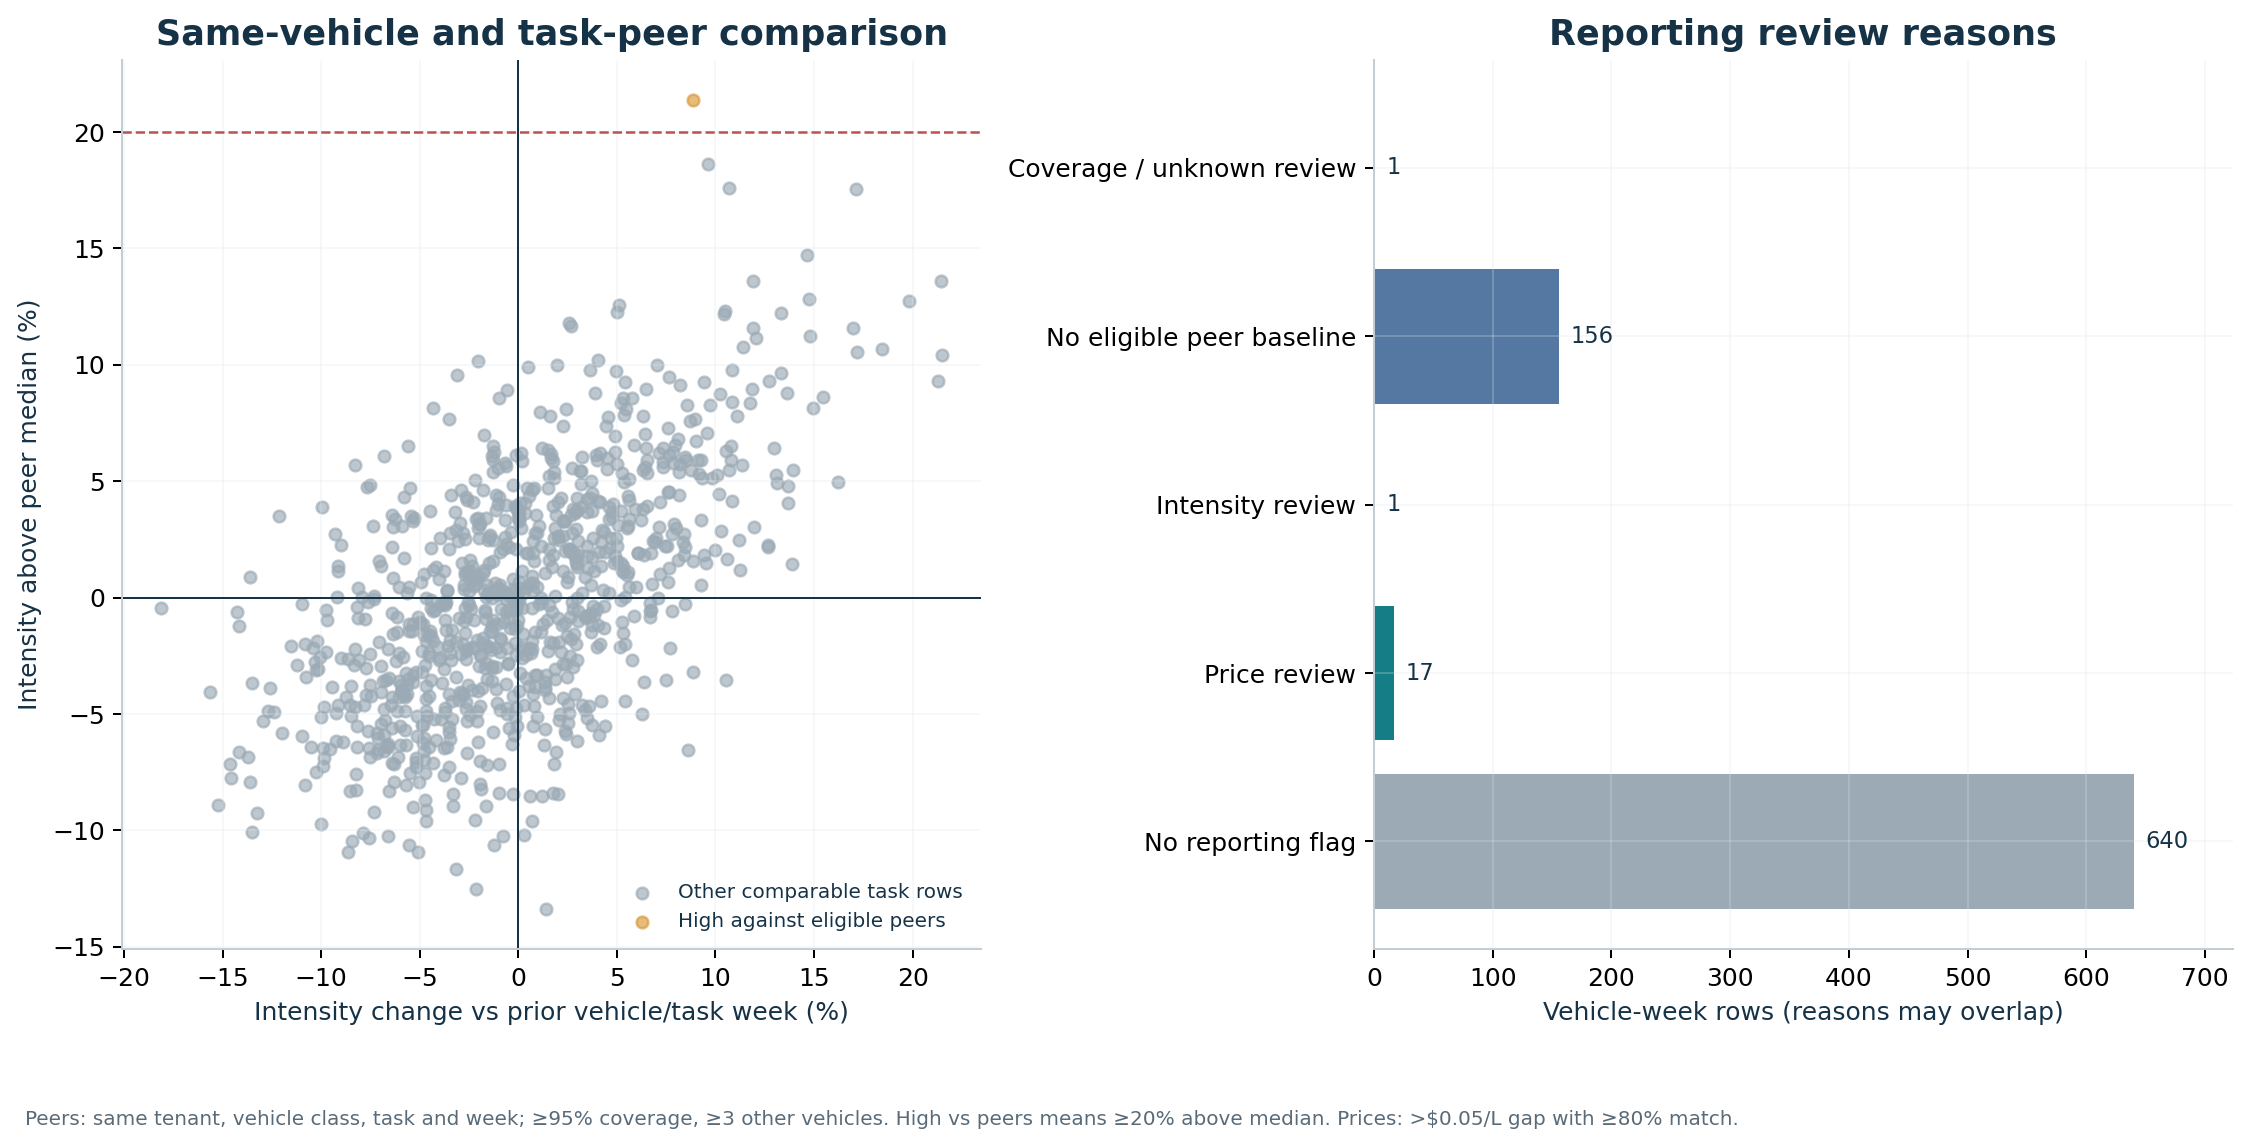

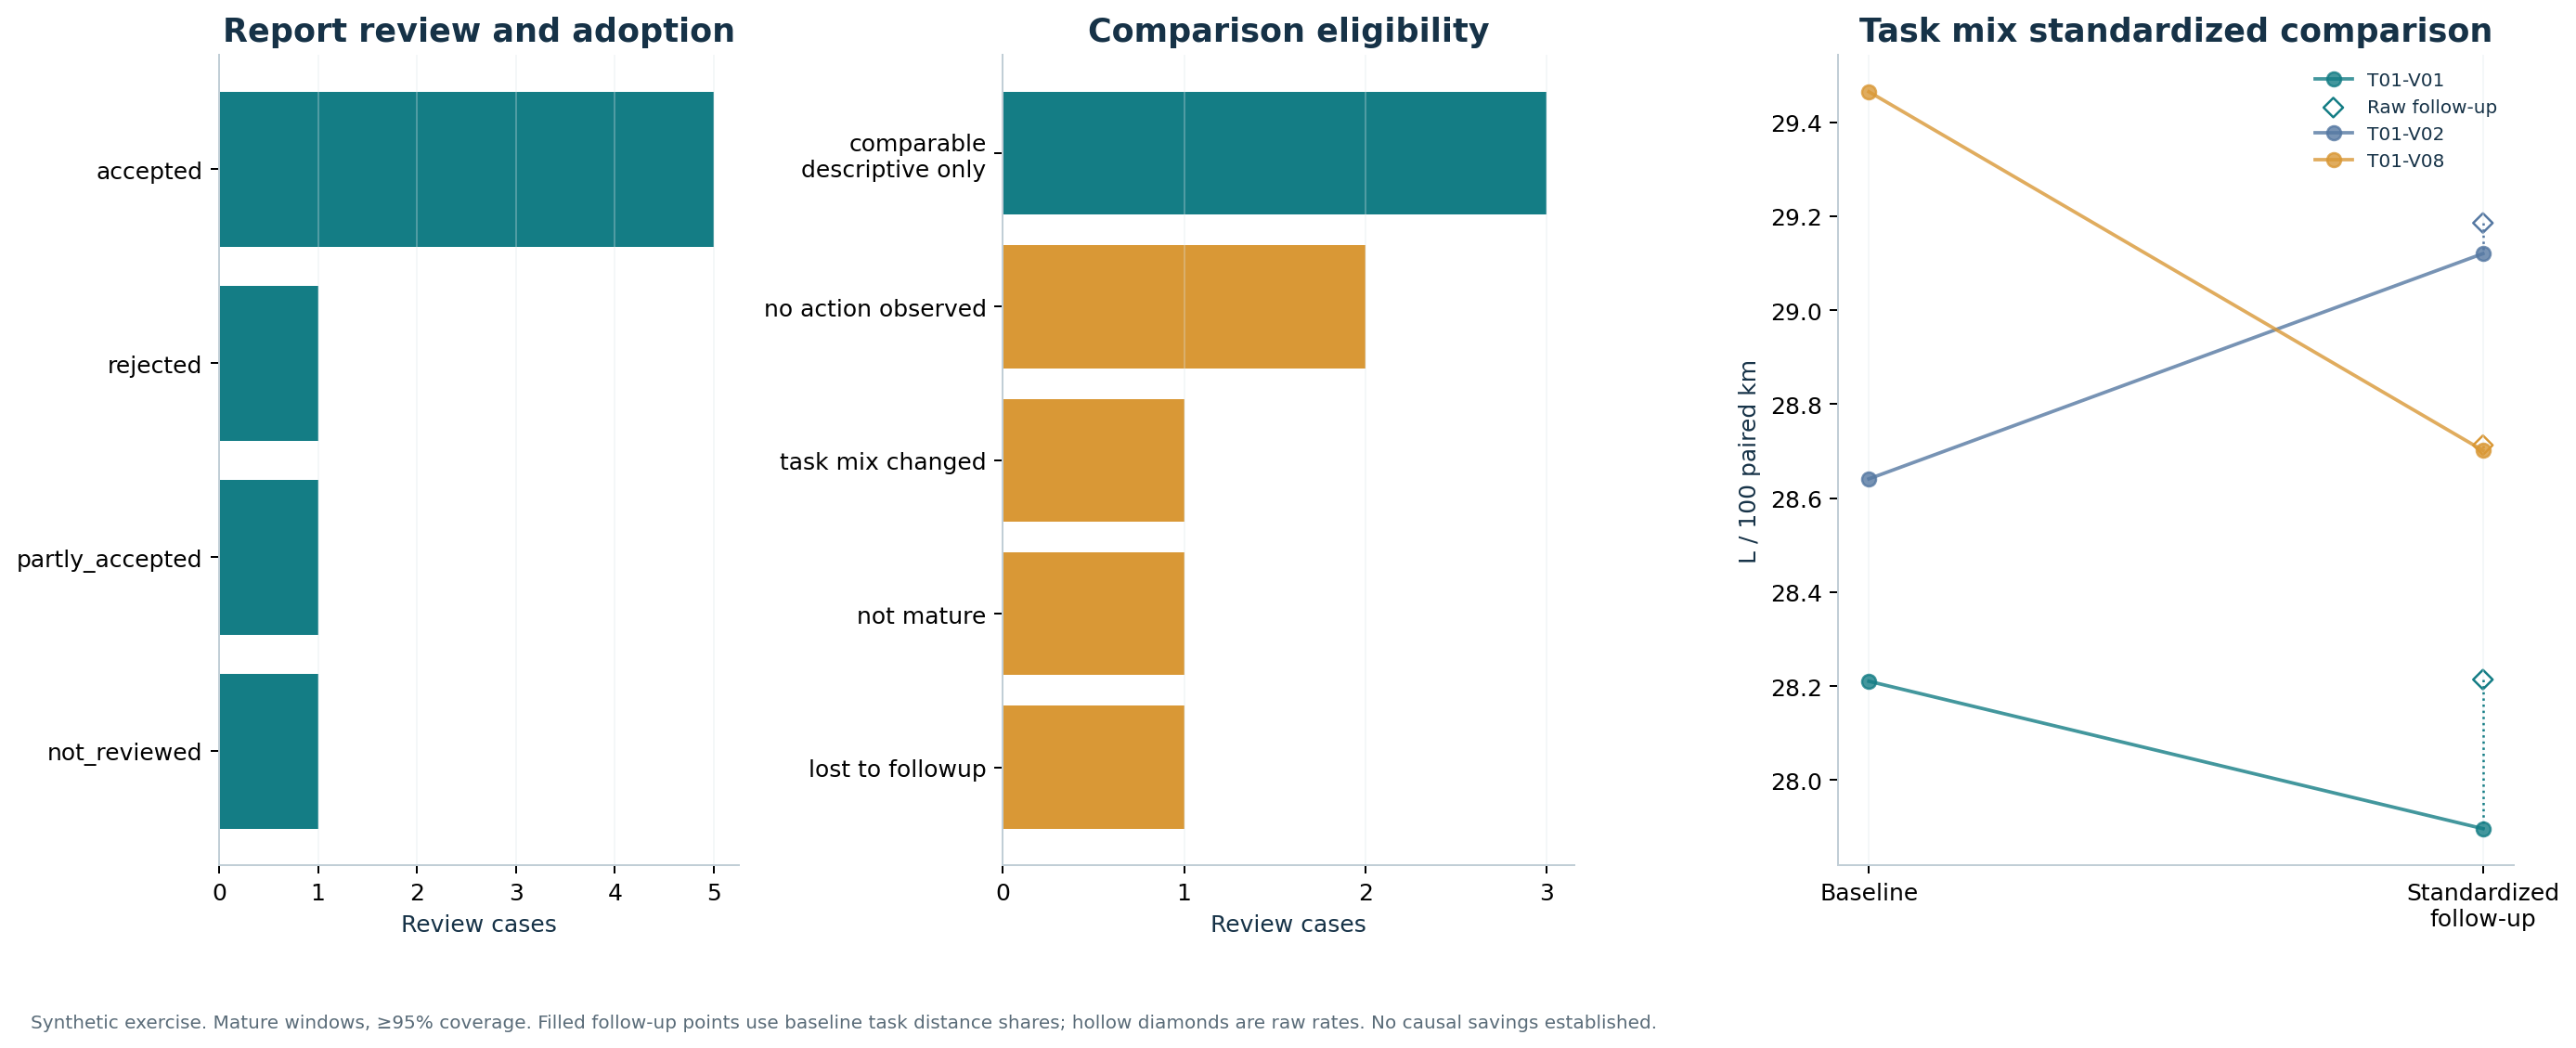

In [11]:
from IPython.display import Image, display
display(Image(filename=str(root / 'outputs/figures/06_review_priority.png')))
display(Image(filename=str(root / 'outputs/figures/07_action_followup.png')))

In [12]:
con.close()